Q8: Interacting with Web APIs

Analyzing weather data for London using OpenWeatherMap.

Install requests, pandas, seaborn, matplotlib and folium. Paste your API key in the first code cell before running.

The saved outputs were generated from a live OpenWeatherMap forecast for London.

In [1]:
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import folium

# Enter the API key
API_KEY = "PASTE_YOUR_API_KEY_HERE"
city = "London"
url = "https://api.openweathermap.org/data/2.5/forecast"
params = {"q": city, "appid": API_KEY, "units": "metric"}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
data = response.json()
print(data)

{'cod': '200', 'message': 0, 'cnt': 40, 'list': [{'dt': 1793016000, 'main': {'temp': 11.74, 'feels_like': 11.35, 'temp_min': 11.74, 'temp_max': 12.68, 'pressure': 1009, 'sea_level': 1009, 'grnd_level': 1005, 'humidity': 91, 'temp_kf': -0.94, 'dew_point': 10.32}, 'weather': [{'id': 501, 'main': 'Rain', 'description': 'moderate rain', 'icon': '10d'}], 'clouds': {'all': 100}, 'wind': {'speed': 5.74, 'deg': 184, 'gust': 11.92}, 'visibility': 3843, 'pop': 1, 'rain': {'3h': 3.45}, 'sys': {'pod': 'd'}, 'dt_txt': '2026-10-26 12:00:00'}, {'dt': 1793026800, 'main': {'temp': 13.74, 'feels_like': 13.57, 'temp_min': 13.74, 'temp_max': 14.97, 'pressure': 1008, 'sea_level': 1008, 'grnd_level': 1004, 'humidity': 92, 'temp_kf': -1.23, 'dew_point': 12.46}, 'weather': [{'id': 500, 'main': 'Rain', 'description': 'light rain', 'icon': '10d'}], 'clouds': {'all': 100}, 'wind': {'speed': 5.5, 'deg': 217, 'gust': 11.98}, 'visibility': 10000, 'pop': 0.2, 'rain': {'3h': 0.62}, 'sys': {'pod': 'd'}, 'dt_txt': '202

In [2]:
# Extract weather data
records = []
for record in data["list"]:
    weather = {
        "Date": record["dt_txt"],
        "Temperature": record["main"]["temp"],
        "Humidity": record["main"]["humidity"],
        "Wind_Speed": record["wind"]["speed"],
        "Rain": record.get("rain", {}).get("3h", 0)
    }
    records.append(weather)

df = pd.DataFrame(records)
print("Weather Data:")
print(df.head())
print("\nShape:", df.shape)

Weather Data:
                  Date  Temperature  Humidity  Wind_Speed  Rain
0  2026-10-26 12:00:00        11.74        91        5.74  3.45
1  2026-10-26 15:00:00        13.74        92        5.50  0.62
2  2026-10-26 18:00:00        14.52        90        5.39  0.00
3  2026-10-26 21:00:00        14.32        86        5.96  0.00
4  2026-10-27 00:00:00        14.78        89        6.00  0.00

Shape: (40, 5)


In [3]:
# Clean the data
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna().drop_duplicates()
df = df.sort_values("Date").reset_index(drop=True)

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date           0
Temperature    0
Humidity       0
Wind_Speed     0
Rain           0
dtype: int64


In [4]:
# Calculate weather statistics
print("Average Temperature:", df["Temperature"].mean())
print("Maximum Temperature:", df["Temperature"].max())
print("Minimum Temperature:", df["Temperature"].min())
print("Average Humidity:", df["Humidity"].mean())
print("Total Rain:", df["Rain"].sum())

# Daily aggregation
daily = df.groupby(df["Date"].dt.date).agg({
    "Temperature": "mean",
    "Humidity": "mean",
    "Wind_Speed": "mean",
    "Rain": "sum"
})

print("\nDaily Weather Summary:")
print(daily)

Average Temperature: 11.248249999999999
Maximum Temperature: 15.32
Minimum Temperature: 6.92
Average Humidity: 86.8
Total Rain: 7.470000000000001

Daily Weather Summary:
            Temperature  Humidity  Wind_Speed  Rain
Date                                               
2026-10-26     13.58000     89.75      5.6475  4.07
2026-10-27     13.16500     78.00      4.9450  3.25
2026-10-28     11.29875     80.00      3.0400  0.00
2026-10-29     10.40375     91.50      1.3475  0.15
2026-10-30     10.75250     90.00      1.4575  0.00
2026-10-31      7.66250     99.25      0.4950  0.00


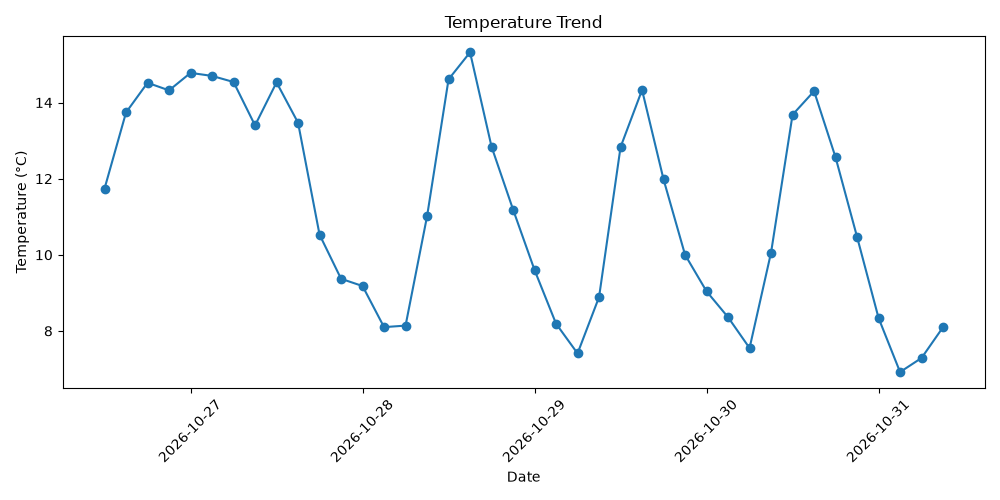

In [5]:
# Temperature trend
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Temperature"], marker="o")
plt.title("Temperature Trend")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

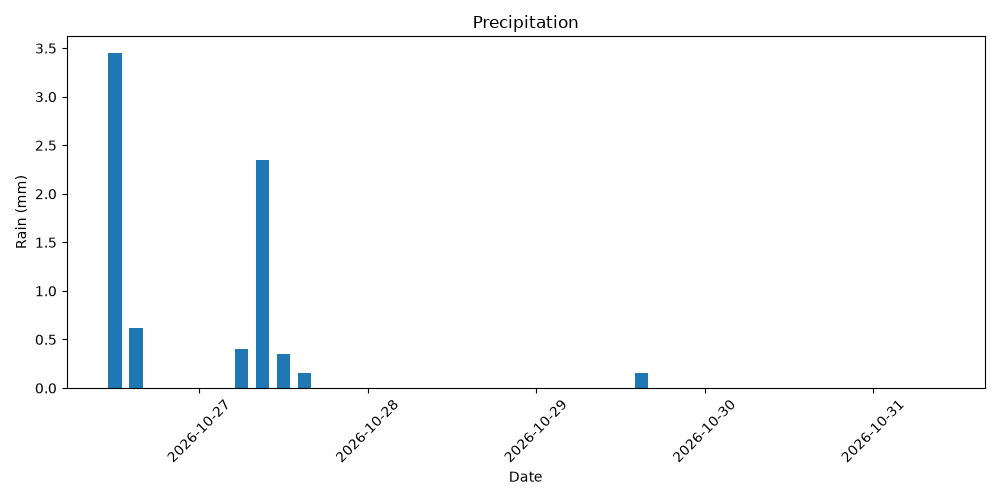

In [6]:
# Rainfall
plt.figure(figsize=(10, 5))
plt.bar(df["Date"], df["Rain"], width=0.08)
plt.title("Precipitation")
plt.xlabel("Date")
plt.ylabel("Rain (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

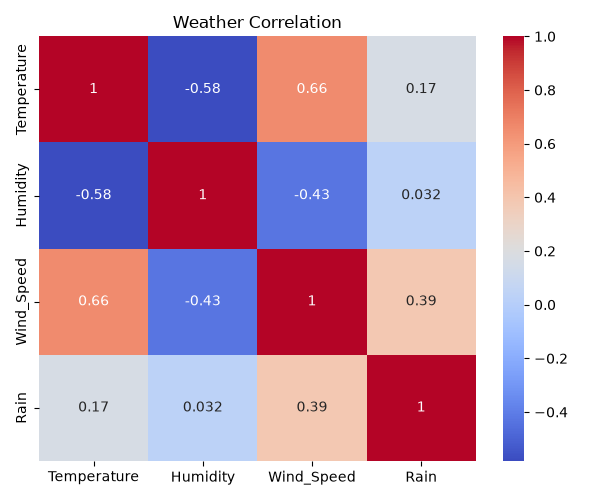

In [7]:
# Correlation heatmap
corr = df[["Temperature", "Humidity", "Wind_Speed", "Rain"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Weather Correlation")
plt.tight_layout()
plt.show()

In [8]:
# Geographical map
lat = data["city"]["coord"]["lat"]
lon = data["city"]["coord"]["lon"]

m = folium.Map(location=[lat, lon], zoom_start=10)
folium.Marker([lat, lon], popup=city).add_to(m)
m.save("weather_map.html")

print("Map saved as weather_map.html")

Map saved as weather_map.html
